Shape: (768, 9)
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.95221

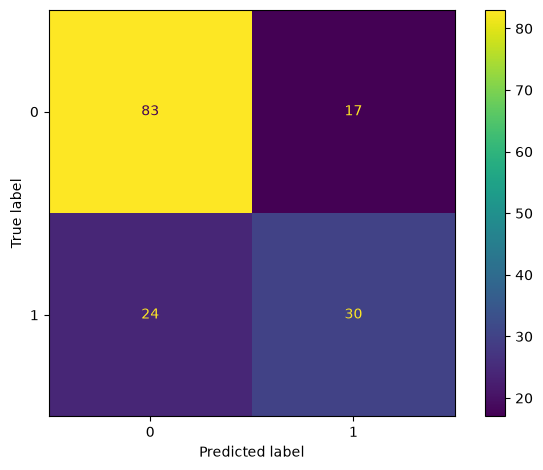

In [1]:
"""B4: Diabetes prediction using KNN and evaluation metrics."""
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score,
    f1_score, classification_report, ConfusionMatrixDisplay
)

DATA_URL = "https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv"
df = pd.read_csv(DATA_URL)

print("Shape:", df.shape)
print(df.head())
print(df.describe())
print("Missing values:\n", df.isnull().sum())
print("Outcome distribution:\n", df["Outcome"].value_counts())

X = df.drop(columns=["Outcome"]).copy()
y = df["Outcome"].copy()

# In this dataset, zero is an invalid/missing value in these measurements.
zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
X[zero_as_missing] = X[zero_as_missing].replace(0, np.nan)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Fit imputation and scaling on training data only.
pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier()),
])

# Select K using cross-validation on training data, not the final test set.
parameters = {"knn__n_neighbors": list(range(1, 21))}
grid = GridSearchCV(pipeline, parameters, cv=5, scoring="accuracy")
grid.fit(X_train, y_train)
print("Best K:", grid.best_params_["knn__n_neighbors"])

best_model = grid.best_estimator_
predictions = best_model.predict(X_test)

cm = confusion_matrix(y_test, predictions)
tn, fp, fn, tp = cm.ravel()
accuracy = accuracy_score(y_test, predictions)

print("\nConfusion matrix:\n", cm)
print("TP =", tp, "TN =", tn, "FP =", fp, "FN =", fn)
print("Accuracy  :", accuracy)
print("Error rate:", 1 - accuracy)
print("Precision :", precision_score(y_test, predictions, zero_division=0))
print("Recall    :", recall_score(y_test, predictions, zero_division=0))
print("F1 score  :", f1_score(y_test, predictions, zero_division=0))
print(classification_report(y_test, predictions, zero_division=0))

ConfusionMatrixDisplay(confusion_matrix=cm).plot()
plt.tight_layout()
plt.show()
